# Imports

##### standard python libraries

In [1]:
import pandas as pd
from sqlalchemy import create_engine

In [2]:
from pysdl import SDLClient

In [3]:
import warnings
warnings.filterwarnings('ignore')

##### Custom Libraries

In [4]:
import psql_utilities as psql_utl
import plot_utilities as plt_utl

### Set Paths

In [5]:
### path to configuration file of database
path_conf_file = './../../config/database.ini'
### path where to temporary store the file downloaded from SDL
path_tmp_download = '../../sample_data/download_tmp'

### Connect to SDL

In [6]:
client = SDLClient()
client.auth.login()

{'response': 200, 'message': 'Authenticated on SDL successfully.'}


{'message': 'User already attached as andrea.distefano@ingv.it.'}

### Database Connection

In [7]:
db_config = psql_utl.load_config(path_conf_file)
#db_conn = psql_utl.connect(db_config)
### connect to the database - sqlalchemy
engine = create_engine(db_config['db_uri'])

## Sensitivity Analysis: Sensitivity of Inundation to the Manning Friction

In this notebook we perform a simple sensitivity analysis of Tsunami Simulations as described in 
> Gibbons SJ, Lorito S, de la Asunción M, Volpe M, Selva J, Macías J, Sánchez-Linares C, Brizuela B, Vöge M, Tonini R, Lanucara P, Glimsdal S, Romano F, Meyer JC and Løvholt F (2022),
>*The Sensitivity of Tsunami Impact to Earthquake Source Parameters and Manning Friction in High-Resolution Inundation Simulations*,
>*Front. Earth Sci.*, 9:757618,
>doi: 10.3389/feart.2021.757618
In particular, we test the sensitivity of the inundation with respect to the Manning friction. 

In order to select the relevant scenarios for the analysis we consider all events 
  1. whose epicenter is located in a given region (*Event Location*)
  2. with fixed value of *Magnitude*, *Dip*, *Rake*, *Strike* and *Slip*.
For this events we consider results of simulations obtained will all possible values of *Manning Coefficient*. 
  3. As an example of the analysis, we plot the cumulative inundation areas in the bay of Catania obtained from the different Manning Coefficient values. Again, we use SDL API to access the output files of the simulatons.

The query used to perform the above analysis is similar to the one described in the what-if analysis, see *'./query_sensitivity.sql'*. By varying the value of the input parameter one can perform other sensitivity analysis.

### setup

##### read query from file

In [8]:
query_params = open("./query_sensitivity_v1.sql", "r")
query_params = query_params.read()

##### set input variables

In [19]:
# magnitude
mag_min = 6.8
mag_max = 6.8
# manning coefficient
manning_min = 0.01
manning_max = 0.02
# fault lenght
fault_lenght_min = 30
fault_lenght_max = 35
# fault width
fault_width_min = 15
fault_width_max = 20
# strike
strike_min = 67.5
strike_max = 67.5
# dip
dip_min = 50
dip_max = 50
# rake
rake_min = 270
rake_max = 270
# slip
slip_min = 0.9
slip_max = 1
#
ev_bbox = [15.79,36.92,7.1,15.8,36.93,7.11]
#
bbox_ct = [15.0,37.2,15.15,37.6]
bbox_sr = [15.2,37.0,15.35,37.2]
bbox_all = [0,0,100,100]
area_bbox = bbox_ct

### query result

##### define input parameters

In [20]:
dict_params = {'mag_min': mag_min,
               'mag_max': mag_max,
               'manning_min': manning_min,
               'manning_max': manning_max,
               'fault_lenght_min': fault_lenght_min,
               'fault_lenght_max': fault_lenght_max,
               'fault_width_min': fault_width_min,
               'fault_width_max': fault_width_max,
               'strike_min': strike_min,
               'strike_max': strike_max,
               'dip_min': dip_min,
               'dip_max': dip_max,
               'rake_min': rake_min,
               'rake_max': rake_max,
               'slip_min': slip_min,
               'slip_max': slip_max,
               'ev_bbox': ev_bbox,
               'area_bbox': area_bbox
              }

##### run query with pandas

In [21]:
df_ds_params = pd.read_sql(query_params, con=engine, params=dict_params)
df_ds_params

,ds_path,ds_name,sr_id,sr_path,scen_name,fk_sr_id,seismicity_type,magnitude,manning_coeff,slip_bs_ps,...,fault_centre_lon,fault_centre_lat,fault_centre_depth,fault_lenght,fault_width,strike,dip,mesh_fault_bc_lon,mesh_fault_bc_lat,mesh_fault_bbox
0,CT-SR_M100/BS_001/E01470N3877E01631N3641-BS-M6...,C_CT.nc,sr_22519,CT-SR_M100/BS_001/E01470N3877E01631N3641-BS-M6...,E01470N3877E01631N3641-BS-M680_E01579N3692_D01...,sr_22519,BS,6.8,0.01,0.951357,...,15.797,36.9278,7.107,34.388459,18.556,67.5,50.0,None,None,None
1,CT-SR_M100/BS_002/E01470N3877E01631N3641-BS-M6...,C_CT.nc,sr_42359,CT-SR_M100/BS_002/E01470N3877E01631N3641-BS-M6...,E01470N3877E01631N3641-BS-M680_E01579N3692_D01...,sr_42359,BS,6.8,0.02,0.951357,...,15.797,36.9278,7.107,34.388459,18.556,67.5,50.0,None,None,None


### Compare Inundated Area

##### download file from API

**NOTE:** To run the code below, one needs an SDL account and must be logged in.

In [13]:
dict_stats = plt_utl.get_inundation_area_from_dataset(df_ds=df_ds_params,path_exp=path_tmp_download,sdl_client=client)

Download File CT-SR_M100/BS_001/E01470N3877E01631N3641-BS-M680_E01579N3692_D010_S067D50R270_A000638_S009/C_CT.nc from SDL and save to ../../sample_data/download_tmp/CT-SR_M100__BS_001__E01470N3877E01631N3641-BS-M680_E01579N3692_D010_S067D50R270_A000638_S009__C_CT.nc


{
  "status": "ok",
  "message": "Download CT-SR_M100/BS_001/E01470N3877E01631N3641-BS-M680_E01579N3692_D010_S067D50R270_A000638_S009/C_CT.nc completed successfully!"
}

Download File CT-SR_M100/BS_002/E01470N3877E01631N3641-BS-M680_E01579N3692_D010_S067D50R270_A000638_S009/C_CT.nc from SDL and save to ../../sample_data/download_tmp/CT-SR_M100__BS_002__E01470N3877E01631N3641-BS-M680_E01579N3692_D010_S067D50R270_A000638_S009__C_CT.nc


{
  "status": "ok",
  "message": "Download CT-SR_M100/BS_002/E01470N3877E01631N3641-BS-M680_E01579N3692_D010_S067D50R270_A000638_S009/C_CT.nc completed successfully!"
}

Download File CT-SR_M100/BS_003/E01470N3877E01631N3641-BS-M680_E01579N3692_D010_S067D50R270_A000638_S009/C_CT.nc from SDL and save to ../../sample_data/download_tmp/CT-SR_M100__BS_003__E01470N3877E01631N3641-BS-M680_E01579N3692_D010_S067D50R270_A000638_S009__C_CT.nc


{
  "status": "ok",
  "message": "Download CT-SR_M100/BS_003/E01470N3877E01631N3641-BS-M680_E01579N3692_D010_S067D50R270_A000638_S009/C_CT.nc completed successfully!"
}

Download File CT-SR_M100/BS_004/E01470N3877E01631N3641-BS-M680_E01579N3692_D010_S067D50R270_A000638_S009/C_CT.nc from SDL and save to ../../sample_data/download_tmp/CT-SR_M100__BS_004__E01470N3877E01631N3641-BS-M680_E01579N3692_D010_S067D50R270_A000638_S009__C_CT.nc


{
  "status": "ok",
  "message": "Download CT-SR_M100/BS_004/E01470N3877E01631N3641-BS-M680_E01579N3692_D010_S067D50R270_A000638_S009/C_CT.nc completed successfully!"
}

Download File CT-SR_M100/BS_005/E01470N3877E01631N3641-BS-M680_E01579N3692_D010_S067D50R270_A000638_S009/C_CT.nc from SDL and save to ../../sample_data/download_tmp/CT-SR_M100__BS_005__E01470N3877E01631N3641-BS-M680_E01579N3692_D010_S067D50R270_A000638_S009__C_CT.nc


{
  "status": "ok",
  "message": "Download CT-SR_M100/BS_005/E01470N3877E01631N3641-BS-M680_E01579N3692_D010_S067D50R270_A000638_S009/C_CT.nc completed successfully!"
}

##### plot data 

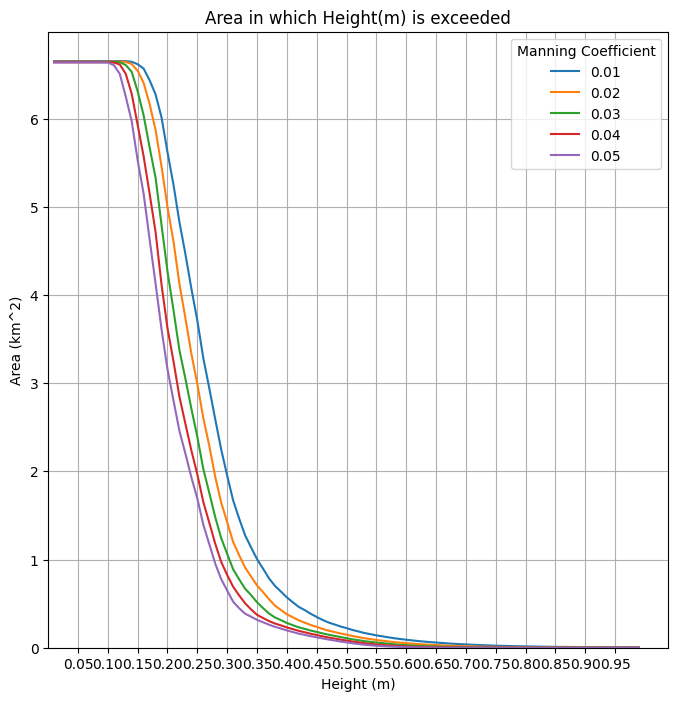

In [14]:
plot = plt_utl.show_comparison_plot(dict_data=dict_stats,variable_key='manning_coeff',variable_label="Manning Coefficient")

### NOTE (access dataset locally)

If the experiment files have already been downloaded, one can specify the path where the experiment is located (*path_experiment_dataset*):

   dict_stats = plt_utl.get_inundation_area_from_dataset(df_ds=df_ds_params,path_exp=path_experiment_dataset,sdl_client=None)

and then plot the data

   plot = plt_utl.show_comparison_plot(dict_data=dict_stats,variable_key='manning_coeff',variable_label="Manning Coefficient")

As a test one can also use the sample data (*path_experiment_dataset = './../../sample_data/'*)  by setting in the query:
   manning_min = 0.01
   manning_max = 0.02